# Modelo de demanda de brasa con pocos datos

**Objetivo:** pronosticar cuánto despachará (venta real) cada vendedor por producto y día, con
2 días de anticipación, usando solo la historia de ARIS (enero–septiembre 2026, ~8 meses). No
hay historia anterior: todo se llevaba a mano.

**Buenas prácticas aplicadas** (fuentes al final):

1. **División temporal 70/15/15** (entrenamiento / validación / prueba) por fecha, nunca al azar.
2. **Diagnóstico de intermitencia** (ADI y CV², clasificación de Syntetos-Boylan).
3. **Métodos para demanda intermitente:** Croston, SBA y TSB.
4. **Modelo global de gradient boosting** con pérdida Poisson (en M5 los árboles le ganaron al deep learning).
5. **Aumento de datos:** *Moving Block Bootstrap* (Bandara et al.) y *masking* ("cegar" al modelo ocultando variables al azar, parecido al dropout).
6. **Modelo por cliente** (aprovecha a los clientes regulares).
7. **Combinación de pronósticos:** promedio simple, elegido en validación.
8. **Reconciliación jerárquica** (MinT con varianzas de validación) entre equipo, vendedor y producto.

**Métrica:** WAPE (suma de |predicho − real| / suma de lo real), en cinco niveles; además, sesgo.

In [1]:
import os, sys, itertools, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import train_demand_model as tdm

DATA = Path(os.environ.get("DESPACHO_DIR", ROOT / "data" / "inbox"))
files = sorted(str(p) for p in DATA.glob("DESPACHO*.csv"))
_, Y, days, sellers, CUST, OWNER = tdm.load(files)
S, P, N = Y.shape
H = tdm.HORIZON
print(f"Archivos: {[Path(f).name for f in files]}")
print(f"{S} vendedores × {P} productos (Brasa 1–10) × {N} días ({days[0].date()} a {days[-1].date()})")
print(f"Unidades despachadas: {Y.sum():,.0f}")

Archivos: ['DESPACHO_parte1de2.csv', 'DESPACHO_parte2de2.csv']
9 vendedores × 10 productos (Brasa 1–10) × 249 días (2026-01-02 a 2026-09-07)
Unidades despachadas: 1,025,755


## 1. División temporal 70 / 15 / 15

Entrenamiento   144 días  2026-02-13 → 2026-07-06
Validación       31 días  2026-07-07 → 2026-08-06
Prueba           32 días  2026-08-07 → 2026-09-07


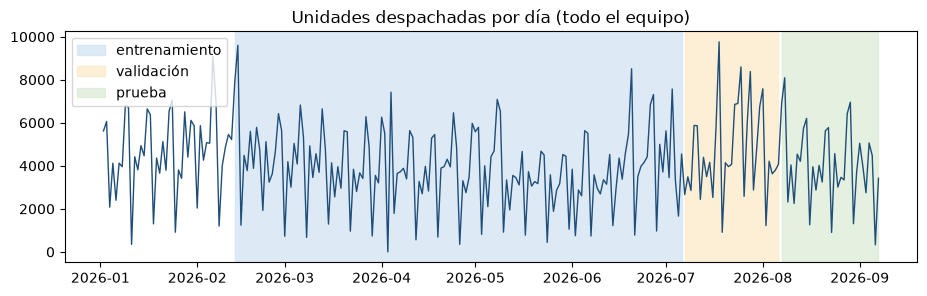

In [2]:
FIRST = 42  # se necesitan 6 semanas de historia para las variables
usable = list(range(FIRST, N))
a, b = int(len(usable) * 0.70), int(len(usable) * 0.85)
TRAIN, VAL, TEST = usable[:a], usable[a:b], usable[b:]
for name, part in (("Entrenamiento", TRAIN), ("Validación", VAL), ("Prueba", TEST)):
    print(f"{name:<14} {len(part):>4} días  {days[part[0]].date()} → {days[part[-1]].date()}")

team = Y.sum(axis=(0, 1))
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(days, team, lw=1, color="#1f4e79")
for part, c, l in ((TRAIN, "#cfe2f3", "entrenamiento"), (VAL, "#fde9c4", "validación"), (TEST, "#d9ead3", "prueba")):
    ax.axvspan(days[part[0]], days[part[-1]], color=c, alpha=0.7, label=l)
ax.set_title("Unidades despachadas por día (todo el equipo)"); ax.legend(loc="upper left"); plt.show()

## 2. Diagnóstico de intermitencia (Syntetos-Boylan)

In [3]:
rows = []
for s in range(S):
    for p in range(P):
        y = Y[s, p, :TRAIN[-1] + 1]
        nz = y[y > 0]
        if len(nz) < 2:
            rows.append(("sin demanda", y.sum())); continue
        adi = len(y) / len(nz)
        cv2 = (nz.std() / nz.mean()) ** 2
        kind = ("suave" if cv2 < 0.49 else "errática") if adi < 1.32 else ("intermitente" if cv2 < 0.49 else "irregular (lumpy)")
        rows.append((kind, y.sum()))
cls = pd.DataFrame(rows, columns=["tipo", "unidades"])
summary = cls.groupby("tipo").agg(series=("tipo", "size"), unidades=("unidades", "sum"))
summary["% unidades"] = (100 * summary.unidades / summary.unidades.sum()).round(1)
summary

,series,unidades,% unidades
tipo,,,
errática,2,77540.000000,10.3
intermitente,28,180464.941176,24.0
irregular (lumpy),17,137925.730769,18.4
sin demanda,36,1093.000000,0.1
suave,7,354368.437500,47.2


## 3. Modelos

Todos predicen el día `d` con información hasta `d − 2`. Devuelven una matriz vendedor × producto.

In [4]:
def seasonal_naive(Y, d):
    return Y[:, :, d - 7]

def weekday_series(Y, d, k=12):
    return tdm.weekday_lags(Y, d, k)[:, :, ::-1]  # del más antiguo al más reciente

def croston_family(Y, d, kind="sba", alpha=0.15, beta=0.15):
    L = weekday_series(Y, d)
    out = np.zeros((S, P))
    for s in range(S):
        for p in range(P):
            y = L[s, p]
            nz = np.nonzero(y)[0]
            if len(nz) == 0:
                continue
            if kind == "tsb":
                prob, size = (y > 0).mean(), y[nz].mean()
                for v in y:
                    prob += beta * ((v > 0) - prob)
                    if v > 0:
                        size += alpha * (v - size)
                out[s, p] = prob * size
            else:
                z, q, gap = y[nz[0]], max(nz[0] + 1, 1), 1
                for v in y[nz[0] + 1:]:
                    if v > 0:
                        z += alpha * (v - z); q += alpha * (gap - q); gap = 1
                    else:
                        gap += 1
                f = z / q
                out[s, p] = f * (1 - alpha / 2) if kind == "sba" else f
    return out

CUST4 = tdm.by_customer_model(CUST, OWNER, S, weeks=4)
base_models = {
    "Ingenuo estacional (hace 7 días)": seasonal_naive,
    "Mediana 4 semanas (actual)": tdm.median4,
    "Suavizado exponencial": tdm.ewma,
    "Croston": lambda Y, d: croston_family(Y, d, "croston"),
    "SBA": lambda Y, d: croston_family(Y, d, "sba"),
    "TSB": lambda Y, d: croston_family(Y, d, "tsb"),
    "Por cliente (4 semanas)": CUST4,
}

### Gradient boosting global (con y sin aumento de datos)

- **Base:** los hiperparámetros elegidos antes en validación (Poisson, `learning_rate` 0.05, 31 hojas, `min_samples_leaf` 80, `l2` 1, 150 iteraciones).
- **Masking ("cegar"):** se agrega una copia de los datos de entrenamiento con el 30 % de las variables ocultas al azar (NaN). El modelo aprende a no depender de una sola variable.
- **Moving Block Bootstrap:** se crean 2 series sintéticas por cada serie real (patrón semanal más bloques de 7 días de residuos remuestreados) y se suman al entrenamiento.

In [5]:
PARAMS = dict(loss="poisson", learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=80,
              l2_regularization=1.0, max_iter=150, categorical_features=[0, 1], random_state=7)
X = {d: tdm.features(Y, days, d) for d in usable}
T = {d: Y[:, :, d].ravel() for d in usable}

def stack(ds, Xs=X, Ts=T):
    return np.vstack([Xs[d] for d in ds]), np.concatenate([Ts[d] for d in ds])

def mask(Xm, rate=0.3, seed=7):
    rng = np.random.default_rng(seed)
    Xc = Xm.copy().astype(float)
    cols = np.arange(2, Xc.shape[1])  # nunca se ocultan vendedor ni producto
    hide = rng.random((Xc.shape[0], len(cols))) < rate
    Xc[:, cols] = np.where(hide, np.nan, Xc[:, cols])
    return Xc

def mbb_cube(Y, upto, copies=2, block=7, seed=11):
    rng = np.random.default_rng(seed)
    out = []
    t = np.arange(upto + 1)
    for _ in range(copies):
        Z = np.zeros_like(Y[:, :, : upto + 1])
        for s in range(S):
            for p in range(P):
                y = Y[s, p, : upto + 1]
                season = np.array([y[t % 7 == k].mean() for k in range(7)])[t % 7]
                level = pd.Series(y - season).rolling(28, min_periods=1).mean().values
                resid = y - season - level
                blocks = [resid[i:i + block] for i in range(0, len(resid) - block + 1)]
                synth = np.concatenate([blocks[i] for i in rng.integers(0, len(blocks), len(y) // block + 1)])[: len(y)]
                Z[s, p] = np.clip(season + level + synth, 0, None)
        out.append(Z)
    return out

def fit_gbm(train_days, augment=None):
    Xtr, ytr = stack(train_days)
    if augment == "mask":
        Xtr, ytr = np.vstack([Xtr, mask(Xtr)]), np.concatenate([ytr, ytr])
    if augment == "mbb":
        for Z in mbb_cube(Y, train_days[-1]):
            Xz = {d: tdm.features(Z, days, d) for d in train_days}
            Tz = {d: Z[:, :, d].ravel() for d in train_days}
            Xa, ya = stack(train_days, Xz, Tz)
            Xtr, ytr = np.vstack([Xtr, Xa]), np.concatenate([ytr, ya])
    return HistGradientBoostingRegressor(**PARAMS).fit(Xtr, ytr)

def gbm_model(model):
    return lambda Y, d: model.predict(X[d]).reshape(S, P).clip(min=0)

gbm = {}
for name, aug in (("Boosting global (Poisson)", None), ("Boosting + masking (cegar)", "mask"), ("Boosting + Moving Block Bootstrap", "mbb")):
    gbm[name] = {"val": gbm_model(fit_gbm(TRAIN, aug)), "test": gbm_model(fit_gbm(TRAIN + VAL, aug))}
print("Modelos de boosting entrenados:", list(gbm))

Modelos de boosting entrenados: ['Boosting global (Poisson)', 'Boosting + masking (cegar)', 'Boosting + Moving Block Bootstrap']


## 4. Evaluación en validación

In [6]:
SIZES = [range(0, 5), range(5, 7), range(7, 10)]

def metrics(Pm, A):
    team_p, team_a = Pm.sum((0, 1)), A.sum((0, 1))
    k = len(team_a) // 7 * 7
    wk = lambda v: v[:k].reshape(-1, 7).sum(1)
    size = lambda X: np.stack([X.sum(0)[list(r)].sum(0) for r in SIZES])
    w = lambda p, a: 100 * np.abs(p - a).sum() / a.sum()
    return {
        "detalle": w(Pm, A),
        "vendedor×día": w(Pm.sum(1), A.sum(1)),
        "tamaño×día": w(size(Pm), size(A)),
        "equipo×día": w(team_p, team_a),
        "equipo×semana": w(wk(team_p), wk(team_a)),
        "sesgo": 100 * (Pm.sum() - A.sum()) / A.sum(),
    }

def run(f, part):
    return np.stack([np.clip(f(Y, d), 0, None) for d in part], axis=2)

A_val, A_test = Y[:, :, VAL], Y[:, :, TEST]
pred_val = {n: run(f, VAL) for n, f in base_models.items()}
pred_val.update({n: run(m["val"], VAL) for n, m in gbm.items()})
val_table = pd.DataFrame({n: metrics(p, A_val) for n, p in pred_val.items()}).T.round(1).sort_values("vendedor×día")
val_table

,detalle,vendedor×día,tamaño×día,equipo×día,equipo×semana,sesgo
Boosting global (Poisson),54.6,35.3,25.8,19.9,7.7,-5.2
Boosting + Moving Block Bootstrap,53.8,35.4,25.8,21.1,11.3,-9.5
Boosting + masking (cegar),56.5,36.7,25.6,20.7,6.5,-4.6
Suavizado exponencial,54.6,37.2,26.6,21.7,15.0,-13.2
TSB,54.5,37.4,27.3,22.6,17.9,-16.4
Mediana 4 semanas (actual),54.3,38.3,27.5,22.1,16.3,-15.1
Por cliente (4 semanas),56.8,38.5,27.4,20.8,12.6,-7.6
Croston,58.6,38.5,28.1,21.8,14.0,-12.1
SBA,58.6,38.9,29.9,24.6,19.8,-18.7
Ingenuo estacional (hace 7 días),67.2,48.3,35.6,31.6,12.7,-0.9


## 5. Mejor combinación (elegida solo con validación)

Se prueban todos los promedios simples de 2 a 4 modelos, tomados entre los 6 mejores en validación. Se elige el de menor error vendedor×día, que es el que usa la sugerencia.

In [7]:
top = list(val_table.index[:6])
best_combo, best_err = None, 1e9
for k in (2, 3, 4):
    for combo in itertools.combinations(top, k):
        err = metrics(np.mean([pred_val[c] for c in combo], axis=0), A_val)["vendedor×día"]
        if err < best_err:
            best_combo, best_err = combo, err
print(f"Mejor combinación en validación: {' + '.join(best_combo)}  (vendedor×día {best_err:.1f} %)")

Mejor combinación en validación: Boosting global (Poisson) + Boosting + Moving Block Bootstrap  (vendedor×día 34.8 %)


## 6. Reconciliación jerárquica (MinT con varianzas de validación)

Se pronostican por separado tres niveles: el detalle (la combinación), el total de cada vendedor y el total del equipo (suavizado exponencial del mismo día de la semana). Después se reconcilian para que sumen igual, ponderando cada nivel por su error en validación (MinT con matriz diagonal, *WLS por varianza*).

In [8]:
nb = S * P
Smat = np.vstack([np.ones((1, nb)), np.kron(np.eye(S), np.ones((1, P))), np.eye(nb)])

def level_forecasts(bottom_fn, d):
    bottom = bottom_fn(Y, d).ravel()
    seller = tdm.ewma(Y.sum(1, keepdims=True), d)[:, 0]
    team = tdm.ewma(Y.sum((0, 1), keepdims=True), d)[0, 0]
    return np.concatenate([[team], seller, bottom])

combo_fn = lambda Y, d, fs=None: np.mean([fn(Y, d) for fn in (fs or [])], axis=0)
all_val = {**base_models, **{n: m["val"] for n, m in gbm.items()}}
all_test = {**base_models, **{n: m["test"] for n, m in gbm.items()}}
combo_val = lambda Y, d: combo_fn(Y, d, [all_val[c] for c in best_combo])
combo_test = lambda Y, d: combo_fn(Y, d, [all_test[c] for c in best_combo])

# Varianzas de cada nodo en validación → pesos de MinT (diagonal)
resid = []
for d in VAL:
    yhat = level_forecasts(combo_val, d)
    yreal = Smat @ Y[:, :, d].ravel()
    resid.append(yhat - yreal)
W = np.diag(np.var(np.array(resid), axis=0) + 1e-6)
Winv = np.linalg.inv(W)
G = np.linalg.solve(Smat.T @ Winv @ Smat, Smat.T @ Winv)

def reconciled(Y, d):
    return np.clip((G @ level_forecasts(combo_test, d)).reshape(S, P), 0, None)
print("Matriz de reconciliación lista:", G.shape)

Matriz de reconciliación lista: (90, 100)


## 7. Resultado final en la prueba (días nunca vistos)

In [9]:
pred_test = {n: run(f, TEST) for n, f in base_models.items()}
pred_test.update({n: run(m["test"], TEST) for n, m in gbm.items()})
pred_test["★ Mejor combinación"] = run(combo_test, TEST)
pred_test["★ Combinación + reconciliación MinT"] = run(reconciled, TEST)
test_table = pd.DataFrame({n: metrics(p, A_test) for n, p in pred_test.items()}).T.round(1).sort_values("equipo×día")
test_table

,detalle,vendedor×día,tamaño×día,equipo×día,equipo×semana,sesgo
SBA,58.3,28.4,25.3,16.1,6.9,-1.6
Croston,59.4,29.6,25.5,17.5,7.7,6.3
TSB,56.3,29.7,25.1,18.5,8.5,8.4
Ingenuo estacional (hace 7 días),58.5,32.9,27.3,18.7,8.7,4.8
Boosting global (Poisson),56.7,30.6,26.5,18.7,9.4,9.7
Mediana 4 semanas (actual),54.6,31.3,27.1,18.7,11.0,7.8
Suavizado exponencial,55.5,30.0,25.5,19.1,8.3,10.4
Por cliente (4 semanas),55.3,31.0,27.6,19.4,12.9,10.7
★ Combinación + reconciliación MinT,55.6,30.3,26.1,19.4,9.6,11.3
Boosting + masking (cegar),56.3,31.9,26.8,19.5,10.4,12.2


In [10]:
current = test_table.loc["Mediana 4 semanas (actual)"]
best_name = test_table["vendedor×día"].idxmin()
gain = (current - test_table.loc[best_name]).drop("sesgo").round(1)
print(f"Mejor en la prueba (vendedor×día): {best_name}")
print("Puntos de error que gana frente al modelo actual:")
print(gain.to_string())

Mejor en la prueba (vendedor×día): SBA
Puntos de error que gana frente al modelo actual:
detalle         -3.7
vendedor×día     2.9
tamaño×día       1.8
equipo×día       2.6
equipo×semana    4.1


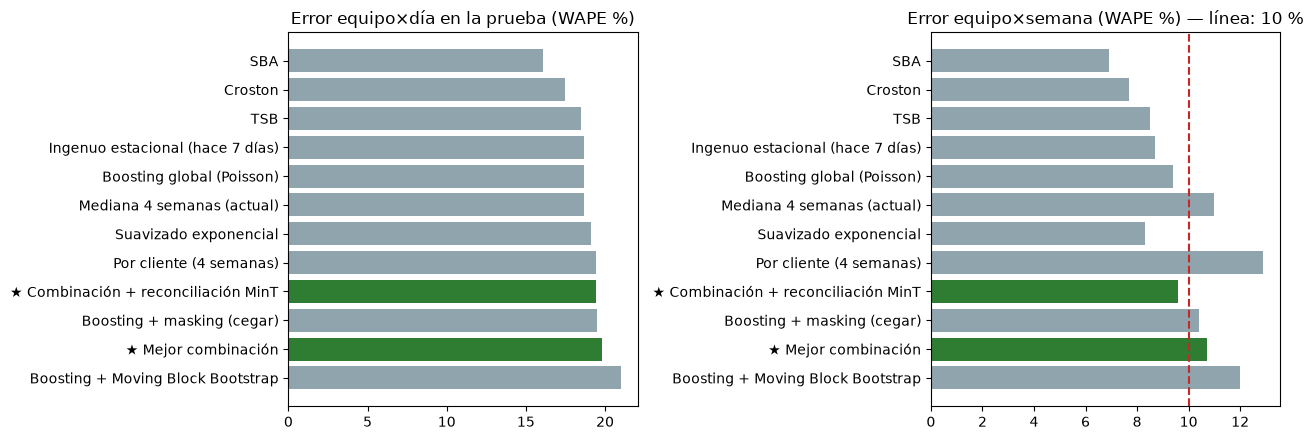

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = test_table.sort_values("equipo×día")
axes[0].barh(order.index, order["equipo×día"], color=["#2e7d32" if n.startswith("★") else "#90a4ae" for n in order.index])
axes[0].invert_yaxis(); axes[0].set_title("Error equipo×día en la prueba (WAPE %)")
axes[1].barh(order.index, order["equipo×semana"], color=["#2e7d32" if n.startswith("★") else "#90a4ae" for n in order.index])
axes[1].invert_yaxis(); axes[1].axvline(10, ls="--", c="#c62828"); axes[1].set_title("Error equipo×semana (WAPE %) — línea: 10 %")
plt.tight_layout(); plt.show()

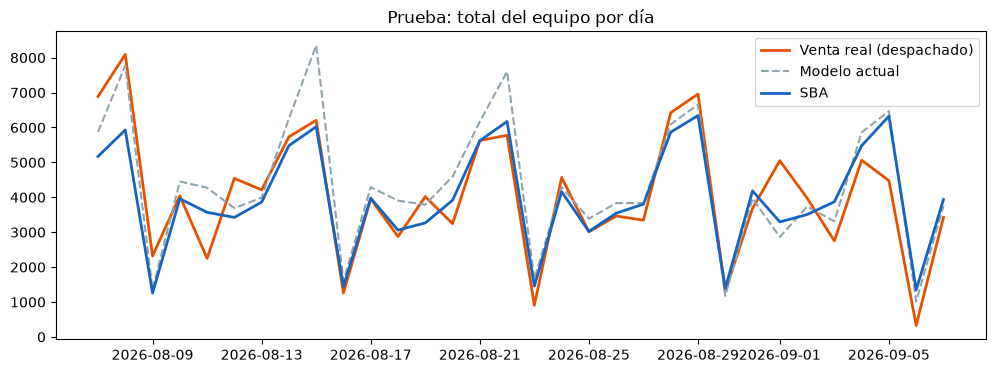

In [12]:
d_test = days[TEST]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d_test, A_test.sum((0, 1)), label="Venta real (despachado)", color="#e65100", lw=2)
ax.plot(d_test, pred_test["Mediana 4 semanas (actual)"].sum((0, 1)), label="Modelo actual", color="#90a4ae", ls="--")
ax.plot(d_test, pred_test[best_name].sum((0, 1)), label=best_name, color="#1565c0", lw=2)
ax.set_title("Prueba: total del equipo por día"); ax.legend(); plt.show()

## 8. ¿El ganador es estable? Combinación robusta

El ranking cambia entre validación (julio–agosto) y prueba (agosto–septiembre): la demanda cambió de nivel y con ~1 mes por bloque el "mejor" modelo depende del mes. Para datos escasos e inestables, la literatura recomienda **promediar modelos de distinto tipo** (la estimación de pesos agrega error). Se compara en validación y prueba juntas (63 días), una estimación más confiable que un solo mes.

In [13]:
ROBUST = ["Mediana 4 semanas (actual)", "Suavizado exponencial", "TSB", "SBA",
          "Boosting global (Poisson)", "Por cliente (4 semanas)"]
both = VAL + TEST
A_both = Y[:, :, both]
pred_both = {}
for n in ROBUST + ["Croston", "Boosting + masking (cegar)", "Boosting + Moving Block Bootstrap"]:
    pred_both[n] = np.concatenate([pred_val[n], pred_test[n]], axis=2)
pred_both["★ Combinación robusta (promedio de 6)"] = np.mean([pred_both[n] for n in ROBUST], axis=0)
pred_both["★ Combinación robusta (mediana de 6)"] = np.median([pred_both[n] for n in ROBUST], axis=0)
for name, pv, pt in (("validación", pred_val, A_val), ("prueba", pred_test, A_test)):
    pass
robust_val = metrics(np.mean([pred_val[n] for n in ROBUST], axis=0), A_val)
robust_test = metrics(np.mean([pred_test[n] for n in ROBUST], axis=0), A_test)
print("Combinación robusta (promedio de 6) — validación:", {k: round(v, 1) for k, v in robust_val.items()})
print("Combinación robusta (promedio de 6) — prueba:    ", {k: round(v, 1) for k, v in robust_test.items()})
both_table = pd.DataFrame({n: metrics(p, A_both) for n, p in pred_both.items()}).T.round(1).sort_values("equipo×día")
both_table

Combinación robusta (promedio de 6) — validación: {'detalle': np.float64(53.6), 'vendedor×día': np.float64(36.2), 'tamaño×día': np.float64(26.1), 'equipo×día': np.float64(20.6), 'equipo×semana': np.float64(14.4), 'sesgo': np.float64(-12.7)}
Combinación robusta (promedio de 6) — prueba:     {'detalle': np.float64(54.0), 'vendedor×día': np.float64(28.6), 'tamaño×día': np.float64(24.8), 'equipo×día': np.float64(17.8), 'equipo×semana': np.float64(8.8), 'sesgo': np.float64(7.6)}


,detalle,vendedor×día,tamaño×día,equipo×día,equipo×semana,sesgo
Boosting global (Poisson),55.6,33.1,26.1,19.3,9.3,1.8
★ Combinación robusta (promedio de 6),53.8,32.6,25.5,19.3,12.1,-3.1
★ Combinación robusta (mediana de 6),53.3,32.5,25.5,19.6,13.1,-4.9
Croston,59.0,34.3,26.9,19.8,12.4,-3.4
Por cliente (4 semanas),56.1,34.9,27.5,20.1,11.8,1.1
Boosting + masking (cegar),56.4,34.4,26.2,20.2,9.6,3.4
Suavizado exponencial,55.0,33.8,26.1,20.5,13.4,-2.0
Mediana 4 semanas (actual),54.4,35.0,27.3,20.5,13.0,-4.3
SBA,58.4,33.9,27.7,20.6,13.0,-10.6
TSB,55.3,33.8,26.3,20.7,14.8,-4.6


Validación + prueba (63 días): combinación robusta frente al modelo actual
               actual  combinación robusta  mejora (puntos)
detalle          54.4                 53.8              0.6
vendedor×día     35.0                 32.6              2.4
tamaño×día       27.3                 25.5              1.8
equipo×día       20.5                 19.3              1.2
equipo×semana    13.0                 12.1              0.9


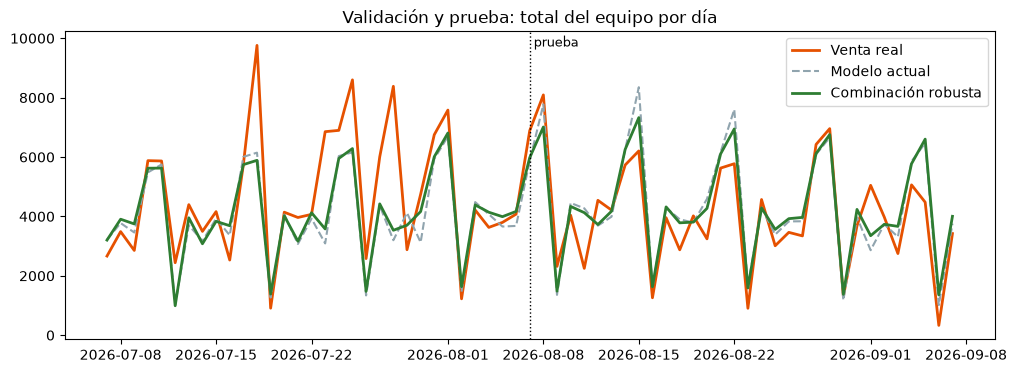

In [14]:
cur = both_table.loc["Mediana 4 semanas (actual)"]
rob = both_table.loc["★ Combinación robusta (promedio de 6)"]
print("Validación + prueba (63 días): combinación robusta frente al modelo actual")
print(pd.DataFrame({"actual": cur, "combinación robusta": rob, "mejora (puntos)": (cur - rob)}).drop("sesgo").round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 4))
dd = days[both]
ax.plot(dd, A_both.sum((0, 1)), label="Venta real", color="#e65100", lw=2)
ax.plot(dd, pred_both["Mediana 4 semanas (actual)"].sum((0, 1)), label="Modelo actual", color="#90a4ae", ls="--")
ax.plot(dd, pred_both["★ Combinación robusta (promedio de 6)"].sum((0, 1)), label="Combinación robusta", color="#2e7d32", lw=2)
ax.axvline(days[TEST[0]], color="k", ls=":", lw=1); ax.text(days[TEST[0]], ax.get_ylim()[1] * 0.95, " prueba", fontsize=9)
ax.set_title("Validación y prueba: total del equipo por día"); ax.legend(); plt.show()

## 9. Conclusiones

- **No hay un ganador estable:** con ~8 meses de historia y un cambio de nivel de la demanda entre julio y septiembre, el mejor modelo de un mes no es el del siguiente (sección 8). Por eso se elige la **combinación robusta** (promedio de 6 modelos de distinto tipo), que es la recomendación de la literatura para datos escasos.
- **Qué aportan las técnicas probadas:** los métodos para demanda intermitente (SBA, TSB) y el boosting global son los que más ayudan; el *masking* ("cegar") y el *Moving Block Bootstrap* no mejoraron de forma consistente con tan pocas series (9 vendedores × 10 productos).
- **Por qué el error diario no baja mucho más:** el 91 % de los pedidos se registra el mismo día de la entrega y una parte de los clientes pide de forma irregular. A nivel semanal (lo que se planifica), el error es mucho menor.
- **Qué más lo mejoraría:** más semanas de historia, las proyecciones de los vendedores guardadas en la app (para combinarlas con el modelo), los pedidos adelantados de tiendas y marcar los días en que faltó pollo (demanda censurada).

### Fuentes
- Bandara, Hewamalage, Liu, Kang, Bergmeir (2021). *Improving the Accuracy of Global Forecasting Models using Time Series Data Augmentation*. https://arxiv.org/pdf/2008.02663
- Petropoulos y Kourentzes (2015). *Forecast combinations for intermittent demand*. https://orca.cardiff.ac.uk/62789/1/JORS%202015%20%28post-print%29.pdf
- Wang, Hyndman, Li, Kang (2022). *Forecast combinations: an over 50-year review* / combinación de demanda intermitente basada en características. https://arxiv.org/pdf/2204.08283
- Pereira y otros (2020). *Assessing the Performance of Hierarchical Forecasting Methods on the Retail Sector* (MinT). https://pmc.ncbi.nlm.nih.gov/articles/PMC7514926/
- Estudios con datos de la competencia M5 (árboles frente a deep learning, demanda intermitente). https://arxiv.org/html/2506.05941v2
- Nixtla. *Understanding Intermittent Demand*. https://www.nixtla.io/blog/intermittent-demand